In [1]:
import pandas as pd

data = pd.read_csv("cleaned_ev_dataset.csv")

print(data.head())
print(data.columns.tolist())

  Session_ID Charger_Type User_Type  Start_Hour  Duration_Mins  Energy_kWh  \
0  SESS-1000           AC     Staff           9          126.0       11.01   
1  SESS-1001           DC   Student           6           35.0       19.78   
2  SESS-1002           DC   Student          10           28.0       13.30   
3  SESS-1003           AC   Student           9           98.0       10.02   
4  SESS-1004           AC   Student          13          104.0       11.12   

   Overstay_Mins  Battery_Temp_C Grid_Status_Label   Power_kW  \
0              0            27.6            Normal   5.242857   
1              0            38.3            Normal  33.908571   
2              0            42.1            Normal  28.500000   
3              0            31.1            Normal   6.134694   
4              6            33.9            Normal   6.415385   

  Energy_Efficiency Peak_Hour  
0            Medium      Peak  
1            Medium  Off-Peak  
2            Medium      Peak  
3           

In [2]:
# Task 2: Feature Selection and Encoding

# Select Charger_Type as the categorical feature
X = pd.get_dummies(
    data[["Charger_Type"]],
    columns=["Charger_Type"],
    dtype=int
)

# Select Grid_Status_Label as the target
y = data["Grid_Status_Label"]

# Display the encoded features
print("Encoded features:")
print(X.head())

# Display the target values
print("\nTarget values:")
print(y.head())

Encoded features:
   Charger_Type_AC  Charger_Type_DC
0                1                0
1                0                1
2                0                1
3                1                0
4                1                0

Target values:
0    Normal
1    Normal
2    Normal
3    Normal
4    Normal
Name: Grid_Status_Label, dtype: object


In [3]:
# Split the data into 80% training and 20% testing

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the training and testing sets
print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

print("\nTraining target size:", y_train.shape)
print("Testing target size:", y_test.shape)

Training data size: (960, 2)
Testing data size: (240, 2)

Training target size: (960,)
Testing target size: (240,)


# Model Training & Comparison

In [4]:
# Task 2: Model Training and Comparison

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Train the Random Forest classifier
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

# Train the Decision Tree classifier
decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train, y_train)

print("Random Forest model trained successfully.")
print("Decision Tree model trained successfully.")

Random Forest model trained successfully.
Decision Tree model trained successfully.


# Performance Evaluation

Random Forest Performance
Accuracy : 0.75
Precision: 0.5625
Recall   : 0.75
F1-score : 0.6428571428571428

Decision Tree Performance
Accuracy : 0.75
Precision: 0.5625
Recall   : 0.75
F1-score : 0.6428571428571428


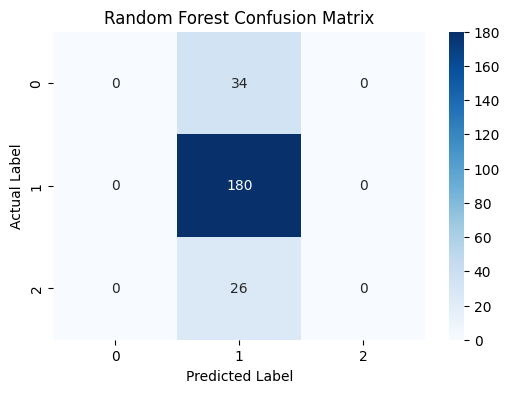

In [5]:
# Task 2: Performance Evaluation

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Make predictions using both trained models
rf_predictions = random_forest.predict(X_test)
dt_predictions = decision_tree.predict(X_test)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions, average='weighted', zero_division=0)
rf_recall = recall_score(y_test, rf_predictions, average='weighted', zero_division=0)
rf_f1 = f1_score(y_test, rf_predictions, average='weighted', zero_division=0)

dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions, average='weighted', zero_division=0)
dt_recall = recall_score(y_test, dt_predictions, average='weighted', zero_division=0)
dt_f1 = f1_score(y_test, dt_predictions, average='weighted', zero_division=0)

# Display Random Forest results
print("Random Forest Performance")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1-score :", rf_f1)

# Display Decision Tree results
print("\nDecision Tree Performance")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1-score :", dt_f1)

# Confusion Matrix for Random Forest
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# Model Persistence

In [6]:
# Task 2: Model Persistence
# Save the highest-performing model using joblib

import joblib

# Both models have the same performance, so Random Forest is selected
best_model = random_forest

# Save the trained model
joblib.dump(best_model, "ev_model.pkl")

print("Best-performing model saved successfully as ev_model.pkl")

Best-performing model saved successfully as ev_model.pkl


In [7]:
# Task 2: Final Model Persistence Check

import os

print("Model file exists:", os.path.exists("ev_model.pkl"))
print("Model saved as: ev_model.pkl")

Model file exists: True
Model saved as: ev_model.pkl
